# SAFE-AI White Paper — NLP Analysis

Tokenize the **Abstract** from the SAFE-AI ethics white paper with NLTK, then run emotional analysis using the **Syuzhet** lexicon workflow (via the Python `moodswing` package, which implements the same Syuzhet/NRC dictionaries as Matthew Jockers' R `syuzhet` package).

In [1]:
from __future__ import annotations

import importlib.util
import re
import subprocess
import sys
from pathlib import Path

REQUIRED_PACKAGES = ("nltk", "moodswing", "pypdf", "matplotlib", "pandas")

missing = [pkg for pkg in REQUIRED_PACKAGES if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"Installing into kernel: {sys.executable}")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing, "-q"]
    )

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from moodswing import DictionarySentimentAnalyzer
from pypdf import PdfReader

for resource in ("punkt", "punkt_tab"):
    nltk.download(resource, quiet=True)

ROOT = Path.cwd().resolve()
if not (ROOT / "SAFE-AI White Paper - Ethics in Medical AI Usage.pdf").exists():
    ROOT = ROOT.parent

PDF_PATH = ROOT / "SAFE-AI White Paper - Ethics in Medical AI Usage.pdf"
print(f"PDF: {PDF_PATH}")
print(f"Exists: {PDF_PATH.exists()}")

Installing into kernel: C:\Users\tnewman\AppData\Local\Python\pythoncore-3.14-64\python.exe
PDF: C:\Users\tnewman\Documents\DDDM\SAFE-AI White Paper - Ethics in Medical AI Usage.pdf
Exists: True


### Extract abstract

In [2]:
def extract_abstract(pdf_path: Path, scan_pages: int = 3) -> str:
    """Pull the abstract section from the white paper PDF."""
    reader = PdfReader(str(pdf_path))
    text = " ".join(
        (page.extract_text() or "") for page in reader.pages[:scan_pages]
    )
    text = re.sub(r"\s+", " ", text).strip()

    start = text.lower().find("abstract")
    end = text.lower().find("introduction")
    if start == -1 or end == -1 or end <= start:
        raise ValueError("Could not locate Abstract / Introduction markers in PDF text.")

    return text[start + len("abstract") : end].strip()


abstract = extract_abstract(PDF_PATH)
print(f"Abstract length: {len(abstract):,} characters")
print("\n" + abstract)

Abstract length: 1,383 characters

Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are often developed for academic or regulatory environments and tend to be comprehensive but overly prescriptive, making them difficult to operationalize within fast-paced, resource-constrained environments. We introduce the Scalable Agile Framework for Execution in AI (SAFE-AI) designed to balance ethical rigor with business priorities by embedding ethical oversight into standard Agile-based product development workflows. The framework emphasizes the early establishment of testable acceptance criteria, fairness metrics, and transparency metrics to manage model uncertainty, while also promoting continuous monitoring and re-evaluation of these metrics across the AI lifecycle. A core component of this framework are responsibility metrics using

### NLTK tokenization

In [3]:
tokens = nltk.word_tokenize(abstract)
alpha_tokens = [t for t in tokens if any(ch.isalpha() for ch in t)]
sentences = nltk.sent_tokenize(abstract)

token_summary = pd.DataFrame(
    {
        "metric": ["sentences", "tokens (all)", "tokens (with letters)"],
        "count": [len(sentences), len(tokens), len(alpha_tokens)],
    }
)
display(token_summary)

print("First 40 tokens:")
print(tokens[:40])

,metric,count
0,sentences,7
1,tokens (all),200
2,tokens (with letters),179


First 40 tokens:
['Artificial', 'intelligence', '(', 'AI', ')', 'offers', 'incredible', 'possibilities', 'for', 'patient', 'care', ',', 'but', 'raises', 'significant', 'ethical', 'issues', ',', 'such', 'as', 'the', 'potential', 'for', 'bias', '.', 'Powerful', 'ethical', 'frameworks', 'exist', 'to', 'minimize', 'these', 'issues', ',', 'but', 'are', 'often', 'developed', 'for', 'academic']


### Syuzhet emotional analysis

Score each sentence with the **Syuzhet** sentiment lexicon (overall valence) and the **NRC** emotion lexicon (anger, anticipation, disgust, fear, joy, sadness, surprise, trust, positive, negative) — the same dictionaries bundled with the R `syuzhet` package.

In [4]:
analyzer = DictionarySentimentAnalyzer()

syuzhet_scores = analyzer.sentence_scores(sentences, method="syuzhet")
nrc_by_sentence = analyzer.nrc_emotions(sentences, language="english")

syuzhet_df = pd.DataFrame(
    {
        "sentence": sentences,
        "syuzhet_score": syuzhet_scores,
    }
)
display(syuzhet_df)

emotion_totals = pd.Series({k: 0.0 for k in nrc_by_sentence[0]})
for row in nrc_by_sentence:
    for emotion, value in row.items():
        emotion_totals[emotion] += value

emotion_totals = emotion_totals.sort_values(ascending=False)
print("\nNRC emotion totals (abstract):")
display(emotion_totals.to_frame("count"))

,sentence,syuzhet_score
0,Artificial intelligence (AI) offers incredible...,3.00
1,Powerful ethical frameworks exist to minimize ...,1.65
2,We introduce the Scalable Agile Framework for ...,1.10
3,The framework emphasizes the early establishme...,2.00
4,A core component of this framework are respons...,1.00
5,This ensures that retraining or tuning activit...,1.25
6,By focusing on the minimum necessary requireme...,2.40



NRC emotion totals (abstract):


,count
positive,21.0
trust,11.0
negative,8.0
fear,6.0
anticipation,3.0
anger,3.0
joy,2.0
disgust,2.0
sadness,1.0
surprise,0.0


### Emotions by sentence

In [6]:
emotion_by_sentence = pd.DataFrame(nrc_by_sentence)
emotion_by_sentence.insert(0, "sentence_id", range(1, len(sentences) + 1))
emotion_by_sentence.insert(1, "sentence", sentences)
emotion_by_sentence.insert(2, "syuzhet_score", syuzhet_scores)

display(emotion_by_sentence)

,sentence_id,sentence,syuzhet_score,anger,anticipation,disgust,fear,joy,negative,positive,sadness,surprise,trust
0,1,Artificial intelligence (AI) offers incredible...,3.00,1.0,1.0,0.0,1.0,1.0,1.0,3.0,0.0,0.0,1.0
1,2,Powerful ethical frameworks exist to minimize ...,1.65,1.0,1.0,1.0,3.0,1.0,2.0,4.0,0.0,0.0,2.0
2,3,We introduce the Scalable Agile Framework for ...,1.10,1.0,0.0,1.0,2.0,0.0,3.0,4.0,1.0,0.0,2.0
3,4,The framework emphasizes the early establishme...,2.00,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,2.0
4,5,A core component of this framework are respons...,1.00,0.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0
5,6,This ensures that retraining or tuning activit...,1.25,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
6,7,By focusing on the minimum necessary requireme...,2.40,0.0,0.0,0.0,0.0,0.0,1.0,4.0,0.0,0.0,2.0


### Plots

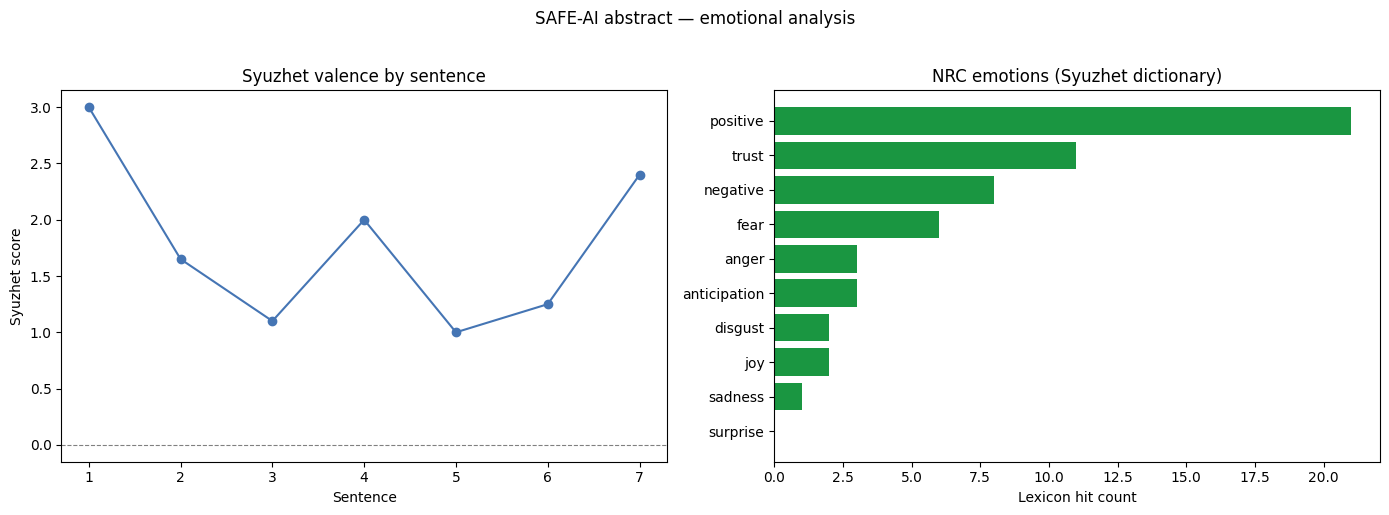

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(syuzhet_scores) + 1), syuzhet_scores, marker="o", color="#4575b4")
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle="--")
axes[0].set_xlabel("Sentence")
axes[0].set_ylabel("Syuzhet score")
axes[0].set_title("Syuzhet valence by sentence")
axes[0].set_xticks(range(1, len(syuzhet_scores) + 1))

emotion_plot = emotion_totals.sort_values(ascending=True)
axes[1].barh(emotion_plot.index, emotion_plot.values, color="#1a9641")
axes[1].set_xlabel("Lexicon hit count")
axes[1].set_title("NRC emotions (Syuzhet dictionary)")

fig.suptitle("SAFE-AI abstract — emotional analysis", y=1.02)
fig.tight_layout()
plt.show()